# SwitchCast: duration loss-weight ablation (Colab)

Trains the causal XLM-R dual-head model once per duration loss weight, using

$$L_{total} = \lambda_{sw} L_{sw} + \lambda_{dur} L_{dur}, \qquad \lambda_{sw} = 1.0,\quad \lambda_{dur} \in \{1.0,\ 0.5,\ 0.3,\ 0.2,\ 0.125\}$$

Nothing else changes between runs: Approach C (neutral punctuation), 14 language pairs, 500 / 150 / 150 rows per pair,
2 utterances per row, 8 epochs, lr 5e-5, AdamW (weight decay 0.01), warmup 0.1, dropout 0.1, seed 42, and the same
pretrained checkpoint, initialisation and data order for every weight.

**Stage 1 (sweep)** reads only the train and validation splits. Each run keeps its best epoch and switch threshold by
validation F1. The weight is chosen by the rule fixed in `loss_weight_ablation_protocol.md`: highest validation switch F1
among runs whose validation duration accuracy is no more than 1 percentage point below the 1.0 / 1.0 control
(ties go to higher duration accuracy).

**Stage 2 (test)** is off by default. Turn it on after the validation table is final; it scores the selected model on
the test split once.

**Before running:** Runtime → Change runtime type → **GPU** (T4 is fine; L4 / A100 are faster), then Runtime → Run all.

| | |
|---|---|
| Time | The earlier 8-epoch XLM-R run took about 32 min on a T4 (~4 min per epoch), so five weights take about **2.7 h**. |
| Disconnects | Each finished run and the best checkpoint so far are saved to Google Drive. Run all again to resume; finished weights are skipped. |
| Drive space | About 2.5 GB free (one 1.1 GB checkpoint, briefly two when a new run takes the lead). |
| Dry run | Set `SMOKE_TEST = True` in the settings for a ~5 min end-to-end check (2 weights, 1 epoch, 10 rows per pair). |

## 1. Settings

In [1]:
# Edit only this cell. Every setting is shared by all runs; only the duration weight changes.

# Loss weights: switch fixed at 1.0, duration varied. 1.0 comes first: it is the equal-weight control.
WEIGHTS = [1.0, 0.5, 0.3, 0.2, 0.125]
SWITCH_WEIGHT = 1.0

# Training (same as the earlier 8-epoch XLM-R / Approach C Colab run)
EPOCHS = 8
LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
DROPOUT = 0.1
SEED = 42
BATCH_SIZE = 32
MAX_LENGTH = 128
ROWS_PER_PAIR = {"train": 500, "validation": 150, "test": 150}
UTTERANCES_PER_ROW = 2
LOG_EVERY = 100  # print the training loss every N steps

# Selection guard: allowed drop in validation duration accuracy vs. the 1.0 / 1.0 control, in percentage points.
MAX_DURATION_DROP_PP = 1.0

# "auto" = BF16 autocast on GPUs with native BF16 (L4, A100, H100) and FP32 on a T4. Or force "bf16" / "fp32".
PRECISION = "auto"

# Results and the current best checkpoint are written to Google Drive after every run.
USE_DRIVE = False
DRIVE_ROOT = "/content/drive/MyDrive/SwitchLingua"
KEEP_ALL_CHECKPOINTS = False  # False: keep only the selected checkpoint (~1.1 GB). True: keep all of them.
RUN_NAME = None  # None -> loss_weight_ablation_colab_<precision>

# Code and data provenance
REPO_URL = "https://github.com/Chuweic/SwitchLingua-Project-CSTeam-1.git"
CODE_COMMIT = "25536acaf653c2eaa5960c73616884687ada78c0"  # same src/ as the Mac sweep
DATA_FOLDER_URL = "https://drive.google.com/drive/folders/1W4y0YEtRhuCIa31Y591JgslPQya9AR5o"
EXPECTED_DATA_SHA256 = {  # hashes of the project's data/processed files
    "train": "51f50db2ebd48fae5fc30a0f7212fb7118c5255e317a2ef1bbe66318999991a4",
    "validation": "0b89560665339b1b1b949e75ded89e09394d74424c181697b4d822ce8e9ca073",
    "test": "a0e823191a6a2d54291d9bbe31f13ca52657f2a2f1561c10727763e2f3574ccb",
}
REQUIRE_SAME_DATA = True

# Quick end-to-end dry run, written to a separate *_smoke folder.
SMOKE_TEST = False
if SMOKE_TEST:
    WEIGHTS = [1.0, 0.5]
    EPOCHS = 1
    ROWS_PER_PAIR = {"train": 10, "validation": 10, "test": 10}
    LOG_EVERY = 5

## 2. GPU and precision

In [2]:
import torch

assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > GPU (T4 is fine)."
DEVICE = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)
capability = torch.cuda.get_device_capability(0)
native_bf16 = capability[0] >= 8

if PRECISION == "auto":
    PRECISION = "bf16" if native_bf16 else "fp32"
assert PRECISION in ("bf16", "fp32"), f"PRECISION must be auto, bf16 or fp32, not {PRECISION!r}"
if PRECISION == "bf16":
    if not native_bf16:
        print(f"WARNING: {GPU_NAME} has no native BF16, so it will be emulated and slow. FP32 is the better choice here.")
    # Make sure a BF16 autocast forward and backward pass really works before training.
    probe = torch.randn(16, 16, device=DEVICE, requires_grad=True)
    with torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        product = probe @ probe
    assert product.dtype == torch.bfloat16, f"autocast produced {product.dtype}, not bfloat16"
    product.float().square().mean().backward()

RUN_NAME = RUN_NAME or f"loss_weight_ablation_colab_{PRECISION}" + ("_smoke" if SMOKE_TEST else "")
print(f"GPU:       {GPU_NAME} (compute capability {capability[0]}.{capability[1]})")
print(f"Precision: {PRECISION}" + (" autocast, FP32 weights" if PRECISION == "bf16" else ""))
print(f"Run name:  {RUN_NAME}")

GPU:       Tesla T4 (compute capability 7.5)
Precision: fp32
Run name:  loss_weight_ablation_colab_fp32


## 3. Code and dependencies

In [3]:
import os
import sys

REPO = "/content/SwitchLingua-Project-CSTeam-1"
if not os.path.exists(REPO):
    !git clone -q {REPO_URL} {REPO}
%cd {REPO}
!git fetch -q origin
!git -c advice.detachedHead=false checkout -q {CODE_COMMIT}
!pip install -q -r requirements.txt gdown
if REPO not in sys.path:
    sys.path.insert(0, REPO)
!git log --oneline -1

/content/SwitchLingua-Project-CSTeam-1
25536ac (HEAD) results: expand French-English LID audit


## 4. Storage (Google Drive)

In [4]:
from pathlib import Path

if USE_DRIVE:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
    except Exception as error:
        raise RuntimeError(
            "Google Drive did not mount. Re-run this cell, click 'Connect to Google Drive', choose your account and "
            "allow access in the popup (allow popups for colab.research.google.com if the browser blocks it). "
            "To run without Drive, set USE_DRIVE = False in the settings; a disconnect then loses all finished runs."
        ) from error
    STORE = Path(DRIVE_ROOT)
else:
    STORE = Path(REPO)  # local only: lost when the runtime disconnects
OUT_DIR = STORE / "results" / RUN_NAME
CKPT_DIR = STORE / "checkpoints" / RUN_NAME
OUT_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

print("Results:    ", OUT_DIR)
print("Checkpoints:", CKPT_DIR)
print("Finished runs found:", sorted(p.stem for p in OUT_DIR.glob("duration_*.json")) or "none")

Results:     /content/SwitchLingua-Project-CSTeam-1/results/loss_weight_ablation_colab_fp32
Checkpoints: /content/SwitchLingua-Project-CSTeam-1/checkpoints/loss_weight_ablation_colab_fp32
Finished runs found: none


## 5. Data

Uses `MyDrive/SwitchLingua/data/processed/*.parquet` if you keep a copy there, otherwise downloads from the team folder.
If both fail, upload `train.parquet`, `validation.parquet` and `test.parquet` to `data/processed/` with the file browser.
The hash check makes sure these are the same files the Mac sweep used. Stage 1 does not read the test split.

In [5]:
import hashlib
import shutil
from pathlib import Path


def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(4 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


# Files uploaded through the Colab Files panel
UPLOAD_DIR = Path("/content")

# Place them where the project expects its data
DATA_DIR = Path(REPO) / "data" / "processed"
DATA_DIR.mkdir(parents=True, exist_ok=True)

SPLITS = ("train", "validation", "test")

for split in SPLITS:
    source = UPLOAD_DIR / f"{split}.parquet"
    target = DATA_DIR / f"{split}.parquet"

    if not source.exists():
        raise FileNotFoundError(
            f"Missing {source}. Upload {split}.parquet using the Files panel."
        )

    shutil.copy2(source, target)
    print(f"Copied {source} -> {target}")


# Verify that all three files exist
missing = [
    split
    for split in SPLITS
    if not (DATA_DIR / f"{split}.parquet").exists()
]

assert not missing, f"Missing data files: {missing}"


# Verify train and validation against the expected project files
DATA_SHA256 = {}

for split in ("train", "validation"):
    path = DATA_DIR / f"{split}.parquet"
    DATA_SHA256[split] = sha256(path)

    same = DATA_SHA256[split] == EXPECTED_DATA_SHA256[split]

    print(
        f"{split:<10} {DATA_SHA256[split][:16]}  "
        f"{'same as the project data' if same else 'DIFFERENT from the project data'}"
    )

    if REQUIRE_SAME_DATA and not same:
        raise RuntimeError(
            f"{split}.parquet is not the expected project file."
        )

print("Data ready:", DATA_DIR)

Copied /content/train.parquet -> /content/SwitchLingua-Project-CSTeam-1/data/processed/train.parquet
Copied /content/validation.parquet -> /content/SwitchLingua-Project-CSTeam-1/data/processed/validation.parquet
Copied /content/test.parquet -> /content/SwitchLingua-Project-CSTeam-1/data/processed/test.parquet
train      51f50db2ebd48fae  same as the project data
validation 0b89560665339b1b  same as the project data
Data ready: /content/SwitchLingua-Project-CSTeam-1/data/processed


## 6. Helpers

In [6]:
import gc
import json
import platform
import subprocess
import time
from datetime import datetime, timezone

import transformers
from src import train as project_train

SOURCE_FILES = ("src/train.py", "src/multitask_model.py", "src/streaming_dataloader.py", "src/switchlingua_labels.py")
# Settings that must match for runs to share a results folder. The soft ones only print a note.
STRICT_KEYS = (
    "code_commit", "source_sha256", "dataset_sha256", "device", "precision", "model", "punctuation_mode",
    "seed", "epochs", "learning_rate", "batch_size", "max_length", "weight_decay", "warmup_ratio",
    "gradient_clip", "dropout", "switch_weight", "rows_per_pair", "utterances_per_row", "language_pairs",
    "weight_candidates", "max_duration_drop_pp",
)
SOFT_KEYS = ("gpu", "pytorch", "transformers", "cuda", "python")


def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False) + "\n", encoding="utf-8")
    os.replace(temporary, path)


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def label_for(weight):
    return "duration_" + str(weight).replace(".", "p")


def result_path(weight):
    return OUT_DIR / f"{label_for(weight)}.json"


def make_model(duration_weight, precision, switch_weight=SWITCH_WEIGHT, dropout=DROPOUT):
    """The project's model, with the forward pass under BF16 autocast when requested."""
    base = project_train.CausalMultitaskModel

    class Model(base):
        def forward(self, *args, **kwargs):
            if precision == "bf16":
                with torch.autocast(device_type=DEVICE.type, dtype=torch.bfloat16):
                    return super().forward(*args, **kwargs)
            return super().forward(*args, **kwargs)

    return Model(model_name="xlm-roberta-base", switch_weight=switch_weight,
                 duration_weight=duration_weight, dropout=dropout)


def build_records(split, tokenizer, rows_per_pair, seed, utterances_per_row):
    return project_train.records_from_parquet(
        str(DATA_DIR / f"{split}.parquet"), tokenizer,
        language_pairs=list(project_train.SELECTED_LANGUAGE_PAIRS),
        max_rows_per_pair=rows_per_pair, max_utterances_per_row=utterances_per_row,
        seed=seed, punctuation_mode="neutral",
    )


def build_loader(records, tokenizer, batch_size, max_length, seed, shuffle, lid_vocab=None):
    return project_train.create_streaming_dataloader(
        records, batch_size=batch_size, shuffle=shuffle, pad_token_id=tokenizer.pad_token_id,
        lid_vocab=lid_vocab, max_length=max_length,
        generator=torch.Generator().manual_seed(seed) if shuffle else None,
    )


def selected_epoch(history):
    return next(entry for entry in history["epochs"] if entry["epoch"] == history["best_epoch"])


def apply_selection_rule(rows):
    """Best validation F1 among runs within MAX_DURATION_DROP_PP of the 1.0 control; ties -> duration accuracy."""
    control = next(row for row in rows if abs(row["duration_weight"] - 1.0) < 1e-9)
    floor = control["validation_duration_accuracy"] - MAX_DURATION_DROP_PP / 100.0
    annotated = [dict(row, passes_duration_guard=row["validation_duration_accuracy"] >= floor) for row in rows]
    eligible = [row for row in annotated if row["passes_duration_guard"]]
    selected = max(eligible, key=lambda row: (row["validation_f1"], row["validation_duration_accuracy"]))
    return selected, annotated, floor


def save_checkpoint(model, path):
    temporary = path.with_name(path.name + ".tmp")
    torch.save({key: value.detach().cpu() for key, value in model.state_dict().items()}, temporary)
    os.replace(temporary, path)


def prune_checkpoints(keep_name):
    for path in CKPT_DIR.glob("duration_*.pt*"):
        if path.name != keep_name:
            path.unlink()


def free_memory():
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE.type == "mps":
        torch.mps.empty_cache()


def experiment_metadata():
    return {
        "date_utc": datetime.now(timezone.utc).isoformat(),
        "runner": "notebooks/loss_weight_ablation_colab.ipynb",
        "code_commit": subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=REPO, text=True).strip(),
        "python": platform.python_version(),
        "pytorch": torch.__version__,
        "transformers": transformers.__version__,
        "cuda": torch.version.cuda,
        "gpu": GPU_NAME,
        "device": DEVICE.type,
        "precision": PRECISION,
        "data_dir": "data/processed",
        "model": "xlm-roberta-base",
        "punctuation_mode": "neutral",
        "seed": SEED,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "max_length": MAX_LENGTH,
        "weight_decay": WEIGHT_DECAY,
        "warmup_ratio": WARMUP_RATIO,
        "gradient_clip": 1.0,
        "dropout": DROPOUT,
        "switch_weight": SWITCH_WEIGHT,
        "rows_per_pair": dict(ROWS_PER_PAIR),
        "utterances_per_row": UTTERANCES_PER_ROW,
        "language_pairs": list(project_train.SELECTED_LANGUAGE_PAIRS),
        "source_sha256": {name: sha256(Path(REPO) / name) for name in SOURCE_FILES},
        "dataset_sha256": dict(DATA_SHA256),
        "weight_candidates": list(WEIGHTS),
        "max_duration_drop_pp": MAX_DURATION_DROP_PP,
        "output_dir": str(OUT_DIR),
        "checkpoint_dir": str(CKPT_DIR),
        "selection_rule": (
            "Maximize validation anticipatory F1 at each run's best validation-selected epoch subject to "
            f"duration accuracy >= equal-weight baseline minus {MAX_DURATION_DROP_PP:g} percentage points; "
            "break ties by validation duration accuracy. Test is held out until selection."
        ),
    }


def differences(current, saved, keys):
    normalise = lambda value: json.loads(json.dumps(value))
    return {key: (saved.get(key), normalise(current.get(key)))
            for key in keys if saved.get(key) != normalise(current.get(key))}


print("Helpers ready. Language pairs:", len(project_train.SELECTED_LANGUAGE_PAIRS))

Helpers ready. Language pairs: 14


## 7. Stage 1: train one model per duration weight

Before each run the RNG and the shuffle order are reset to the same seed, so the runs differ only in $\lambda_{dur}$.
If the runtime disconnects, run all cells again: finished weights are loaded from Drive and skipped, and settings that
would make the runs incomparable stop the cell instead of mixing results.

In [7]:
assert WEIGHTS and abs(WEIGHTS[0] - 1.0) < 1e-9, "Put 1.0 first: it is the control the duration guard is measured against."
assert len(set(WEIGHTS)) == len(WEIGHTS) and min(WEIGHTS) > 0, "Weights must be unique and positive."

config_path = OUT_DIR / "experiment_config.json"
meta = experiment_metadata()
if config_path.exists():
    saved = read_json(config_path)
    changed = differences(meta, saved, STRICT_KEYS)
    if changed:
        details = "\n".join(f"  {key}: before={old!r} now={new!r}" for key, (old, new) in changed.items())
        raise RuntimeError(f"Settings differ from the runs already in {OUT_DIR}:\n{details}\n"
                           "Restore them, or set a new RUN_NAME to start a separate sweep.")
    for key, (old, new) in differences(meta, saved, SOFT_KEYS).items():
        print(f"Note: {key} changed since the first session ({old} -> {new}); each run records its own GPU.")
    meta = saved

pending = [weight for weight in WEIGHTS if not result_path(weight).exists()]
print("Still to train:", [f"{weight:g}" for weight in pending] or "none, all runs are finished")

if pending:
    tokenizer = project_train.load_fast_tokenizer("xlm-roberta-base")
    print("Loading TRAIN and VALIDATION only; the test split is not read in Stage 1.", flush=True)
    train_records = build_records("train", tokenizer, ROWS_PER_PAIR["train"], SEED, UTTERANCES_PER_ROW)
    val_records = build_records("validation", tokenizer, ROWS_PER_PAIR["validation"], SEED, UTTERANCES_PER_ROW)
    train_loader = build_loader(train_records, tokenizer, BATCH_SIZE, MAX_LENGTH, SEED, shuffle=True)
    val_loader = build_loader(val_records, tokenizer, BATCH_SIZE, MAX_LENGTH, SEED, shuffle=False,
                              lid_vocab=train_loader.dataset.lid_vocab)
    data_meta = {
        "record_counts": {"train": len(train_records), "validation": len(val_records)},
        "lid_vocab": train_loader.dataset.lid_vocab,
    }
    if config_path.exists():
        changed = differences(data_meta, meta, data_meta)
        assert not changed, f"Loaded data differs from the first session: {changed}"
    else:
        meta.update(data_meta)
        write_json(config_path, meta)
    print(f"{len(train_records)} train / {len(val_records)} validation records, {len(train_loader)} steps per epoch")

    for weight in pending:
        label = label_for(weight)
        print(f"\n=== switch {SWITCH_WEIGHT:g} / duration {weight:g}  (run {WEIGHTS.index(weight) + 1} of {len(WEIGHTS)}) ===", flush=True)
        project_train.set_seed(SEED)              # same head initialisation and dropout stream
        train_loader.generator.manual_seed(SEED)  # same batch order
        model = make_model(weight, PRECISION)
        started = time.time()
        history = project_train.train_model(
            model, train_loader, val_loader, device=DEVICE, epochs=EPOCHS, learning_rate=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY, warmup_ratio=WARMUP_RATIO, log_every=LOG_EVERY,
        )  # returns with the best validation-F1 epoch restored
        best = selected_epoch(history)
        row = {
            "name": label,
            "switch_weight": SWITCH_WEIGHT,
            "duration_weight": weight,
            "best_epoch": history["best_epoch"],
            "threshold": history["threshold"],
            "validation_f1": best["validation_anticipatory_f1"],
            "validation_duration_accuracy": best["validation_duration_accuracy"],
            "checkpoint_filename": f"{label}.pt",
            "train_minutes": round((time.time() - started) / 60, 2),
            "gpu": GPU_NAME,
        }

        # Keep only the checkpoint that is currently winning under the selection rule.
        finished = [read_json(result_path(w))["candidate"] for w in WEIGHTS if result_path(w).exists()]
        leader, _, _ = apply_selection_rule(finished + [row])
        if KEEP_ALL_CHECKPOINTS or leader["name"] == label:
            save_checkpoint(model, CKPT_DIR / row["checkpoint_filename"])
        write_json(result_path(weight), {
            "run": meta, "candidate": row, "history": history,
            "data_split_usage": "Train on train; epoch and threshold tuned on validation; test not accessed.",
        })
        if not KEEP_ALL_CHECKPOINTS:
            prune_checkpoints(leader["checkpoint_filename"])
        print(f"VALIDATION  F1 {row['validation_f1']:.4f} | duration acc {row['validation_duration_accuracy']:.2%} | "
              f"best epoch {row['best_epoch']} | {row['train_minutes']:.0f} min | "
              f"leading so far: duration {leader['duration_weight']:g}", flush=True)
        del model
        free_memory()

rows = [read_json(result_path(weight))["candidate"] for weight in WEIGHTS]
selected, rows, duration_floor = apply_selection_rule(rows)
write_json(OUT_DIR / "selection.json", {
    "selected": selected, "all_candidates": rows, "metadata": meta,
    "duration_guard_min_accuracy": duration_floor, "selection_uses_test": False,
})
selected_checkpoint = CKPT_DIR / selected["checkpoint_filename"]
print(f"\nSelected: switch {selected['switch_weight']:g} / duration {selected['duration_weight']:g} "
      f"(validation F1 {selected['validation_f1']:.4f}, duration acc {selected['validation_duration_accuracy']:.2%})")
if not selected_checkpoint.exists():
    print(f"WARNING: {selected_checkpoint} is missing; Stage 2 needs it.")

Still to train: ['1', '0.5', '0.3', '0.2', '0.125']


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading TRAIN and VALIDATION only; the test split is not read in Stage 1.


/usr/local/lib/python3.13/dist-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
Building prefix dict from the default dictionary ...
DEBUG:jieba:Building prefix dict from the default dictionary ...
Loading model from cache /tmp/jieba.cache
DEBUG:jieba:Loading model from cache /tmp/jieba.cache
Loading model cost 1.850 seconds.
DEBUG:jieba:Loading model cost 1.850 seconds.
Prefix dict has been built successfully.
DEBUG:jieba:Prefix dict has been built successfully.


12267 train / 3728 validation records, 384 steps per epoch

=== switch 1 / duration 1  (run 1 of 5) ===
epoch 1 step 100/3072 loss 1.5828 (switch 0.4587, duration 1.1241)
epoch 1 step 200/3072 loss 1.2262 (switch 0.2548, duration 0.9714)
epoch 1 step 300/3072 loss 1.1845 (switch 0.2458, duration 0.9387)
epoch 1 done: train loss 1.2946, val loss 1.1365, val F1 0.5062 @ 0.26, val duration acc 0.5710
epoch 2 step 400/3072 loss 1.1580 (switch 0.2233, duration 0.9347)
epoch 2 step 500/3072 loss 1.1194 (switch 0.2192, duration 0.9002)
epoch 2 step 600/3072 loss 1.0736 (switch 0.2075, duration 0.8661)
epoch 2 step 700/3072 loss 1.0765 (switch 0.2070, duration 0.8695)
epoch 2 done: train loss 1.0892, val loss 1.0433, val F1 0.5587 @ 0.25, val duration acc 0.6083
epoch 3 step 800/3072 loss 1.0553 (switch 0.1972, duration 0.8581)
epoch 3 step 900/3072 loss 1.0150 (switch 0.1937, duration 0.8213)
epoch 3 step 1000/3072 loss 1.0199 (switch 0.1892, duration 0.8307)
epoch 3 step 1100/3072 loss 1.014

## 8. Validation results

Validation metrics only, each at that run's best epoch. Writes `validation_summary.csv`, `validation_summary.md`,
`validation_curves.csv` and `selection.json` (same format as `loss_weight_ablation_full.py`).

| Switch weight | Duration weight | Best epoch | Val switch F1 | Val duration acc. | Duration guard |
|---:|---:|---:|---:|---:|---|
| 1.0 | 1 | 8 | 0.5967 | 59.97% | pass |
| 1.0 | 0.5 | 6 | 0.6191 | 60.69% | pass |
| 1.0 | 0.3 | 6 | 0.6290 | 60.26% | pass |
| 1.0 | 0.2 | 5 | 0.6299 | 61.73% | pass |
| 1.0 | 0.125 | 5 | 0.6298 | 61.71% | pass |

Duration guard: validation duration accuracy >= 58.97% (1.0 / 1.0 control minus 1 pp).

Selected: **switch=1.0, duration=0.2**.
This is single-seed model selection. Repeat with additional seeds before strong generalization claims.


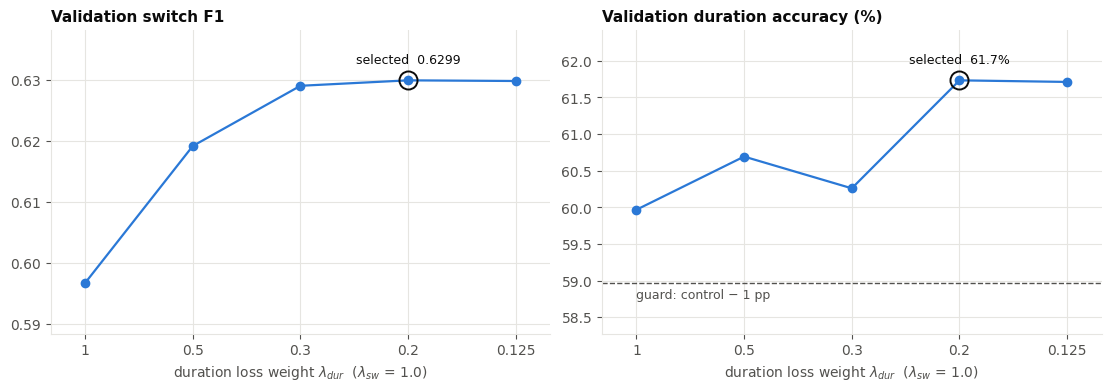

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

# Chart style: light surface, muted axes, fixed series colours (one per weight, in WEIGHTS order).
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
assert len(WEIGHTS) <= len(SERIES)
COLOR = {weight: SERIES[index] for index, weight in enumerate(WEIGHTS)}
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "axes.titlecolor": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

columns = ["name", "switch_weight", "duration_weight", "best_epoch", "threshold", "validation_f1",
           "validation_duration_accuracy", "passes_duration_guard", "train_minutes", "gpu"]
summary = pd.DataFrame(rows)[columns]
summary.to_csv(OUT_DIR / "validation_summary.csv", index=False)

lines = [
    "# XLM-R loss-weight ablation (validation selection)", "",
    f"Colab {', '.join(sorted({row['gpu'] for row in rows}))}, {PRECISION}, batch {BATCH_SIZE}, "
    f"max length {MAX_LENGTH}, {EPOCHS} epochs, seed {SEED}. "
    "The table reports **validation** metrics only. The test set was not used to select weights.", "",
    "| Switch weight | Duration weight | Best epoch | Val switch F1 | Val duration acc. | Duration guard |",
    "|---:|---:|---:|---:|---:|---|",
]
for row in rows:
    lines.append(f"| {row['switch_weight']:.1f} | {row['duration_weight']:g} | {row['best_epoch']} | "
                 f"{row['validation_f1']:.4f} | {row['validation_duration_accuracy']:.2%} | "
                 f"{'pass' if row['passes_duration_guard'] else 'fail'} |")
lines += ["", f"Duration guard: validation duration accuracy >= {duration_floor:.2%} "
          f"(1.0 / 1.0 control minus {MAX_DURATION_DROP_PP:g} pp).", "",
          f"Selected: **switch={selected['switch_weight']}, duration={selected['duration_weight']}**.",
          "This is single-seed model selection. Repeat with additional seeds before strong generalization claims.", ""]
(OUT_DIR / "validation_summary.md").write_text("\n".join(lines), encoding="utf-8")
display(Markdown("\n".join(lines[4:])))

curve_rows = []
for weight in WEIGHTS:
    history = read_json(result_path(weight))["history"]
    for entry in history["epochs"]:
        curve_rows.append({
            "duration_weight": weight, "epoch": entry["epoch"], "seconds": entry["seconds"],
            "train_loss": entry["train_loss"], "train_switch_loss": entry["train_switch_loss"],
            "train_duration_loss": entry["train_duration_loss"], "validation_loss": entry["validation_loss"],
            "validation_switch_loss": entry["validation_switch_loss"],
            "validation_duration_loss": entry["validation_duration_loss"],
            "validation_f1": entry["validation_anticipatory_f1"],
            "validation_duration_accuracy": entry["validation_duration_accuracy"],
            "validation_threshold": entry["validation_threshold"],
            "selected_epoch": entry["epoch"] == history["best_epoch"],
        })
curves = pd.DataFrame(curve_rows)
curves.to_csv(OUT_DIR / "validation_curves.csv", index=False)

# Validation F1 and duration accuracy against the weight: two panels, one measure each.
x = list(range(len(rows)))
f1 = [row["validation_f1"] for row in rows]
accuracy = [100 * row["validation_duration_accuracy"] for row in rows]
chosen = next(i for i, row in enumerate(rows) if row["name"] == selected["name"])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
panels = ((axes[0], f1, "Validation switch F1", "{:.4f}"),
          (axes[1], accuracy, "Validation duration accuracy (%)", "{:.1f}%"))
for ax, values, title, fmt in panels:
    ax.plot(x, values, color=SERIES[0], lw=1.6, marker="o", ms=6, zorder=3)
    ax.plot(x[chosen], values[chosen], marker="o", ms=13, mfc="none", mec=INK, mew=1.4, zorder=4)
    ax.annotate(f"selected  {fmt.format(values[chosen])}", (x[chosen], values[chosen]), textcoords="offset points",
                xytext=(0, 12), ha="center", color=INK, fontsize=9)
    ax.set_xticks(x, [f"{row['duration_weight']:g}" for row in rows])
    ax.set_xlabel(r"duration loss weight $\lambda_{dur}$  ($\lambda_{sw}$ = 1.0)")
    ax.set_title(title)
    ax.margins(x=0.08, y=0.25)
axes[1].axhline(100 * duration_floor, color=INK_MUTED, lw=1, ls="--", zorder=2)
axes[1].annotate(f"guard: control − {MAX_DURATION_DROP_PP:g} pp", (x[0], 100 * duration_floor), textcoords="offset points",
                 xytext=(0, -4), ha="left", va="top", color=INK_MUTED, fontsize=9)
for i, row in enumerate(rows):
    if not row["passes_duration_guard"]:  # hollow marker = fails the guard
        axes[1].plot(x[i], accuracy[i], marker="o", ms=6, mfc="white", mec=SERIES[0], mew=1.6, zorder=4)
fig.savefig(FIG_DIR / "validation_by_weight.png", dpi=200)
plt.show()

## 9. Convergence for both tasks

Losses are the unweighted per-task cross-entropies, so they are comparable across weights (the weighted total is not).
Rings mark the epoch each run kept.

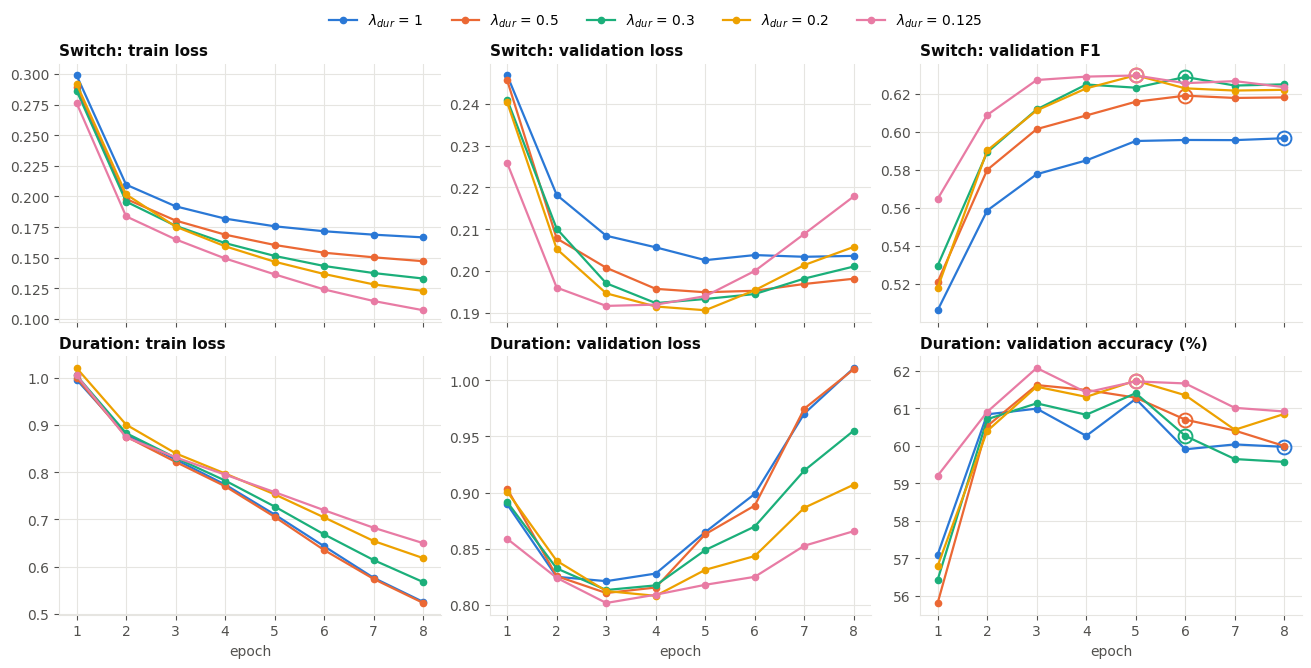

In [9]:
panels = [
    ("train_switch_loss", "Switch: train loss"), ("validation_switch_loss", "Switch: validation loss"),
    ("validation_f1", "Switch: validation F1"),
    ("train_duration_loss", "Duration: train loss"), ("validation_duration_loss", "Duration: validation loss"),
    ("validation_duration_accuracy", "Duration: validation accuracy (%)"),
]
scale = {"validation_duration_accuracy": 100}
fig, axes = plt.subplots(2, 3, figsize=(13, 6.6), sharex=True, constrained_layout=True)
for ax, (column, title) in zip(axes.flat, panels):
    for weight in WEIGHTS:
        run = curves[curves.duration_weight == weight]
        values = run[column] * scale.get(column, 1)
        ax.plot(run.epoch, values, color=COLOR[weight], lw=1.6, marker="o", ms=4.5,
                label=rf"$\lambda_{{dur}}$ = {weight:g}")
        if column in ("validation_f1", "validation_duration_accuracy"):
            kept = run.selected_epoch.to_numpy()
            ax.plot(run.epoch[kept], values[kept], marker="o", ms=10, mfc="none", mec=COLOR[weight], mew=1.4, ls="none")
    ax.set_title(title)
for ax in axes[1]:
    ax.set_xlabel("epoch")
    ax.set_xticks(sorted(curves.epoch.unique()))
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside upper center", ncols=len(WEIGHTS))
fig.savefig(FIG_DIR / "convergence_by_weight.png", dpi=200)
plt.show()

### Reproducibility check (FP32 only)

With FP32, batch 32 and max length 128, the 1.0 / 1.0 run uses the same settings as the earlier
`results/converge_xlmr_neutral_8ep.json` Colab run, so its validation curve should come out close to that one.
Small differences are expected because CUDA kernels are not bitwise deterministic.

In [10]:
reference_path = Path(REPO) / "results" / "converge_xlmr_neutral_8ep.json"
same_setup = (PRECISION == "fp32" and not SMOKE_TEST and (BATCH_SIZE, MAX_LENGTH, EPOCHS, LEARNING_RATE) == (32, 128, 8, 5e-5)
              and ROWS_PER_PAIR == {"train": 500, "validation": 150, "test": 150})
if same_setup and reference_path.exists():
    earlier = read_json(reference_path)["history"]["epochs"]
    now = read_json(result_path(1.0))["history"]["epochs"]
    check = pd.DataFrame({
        "epoch": [entry["epoch"] for entry in now],
        "earlier val F1": [entry["validation_anticipatory_f1"] for entry in earlier],
        "this run val F1": [entry["validation_anticipatory_f1"] for entry in now],
        "earlier val duration acc": [entry["validation_duration_accuracy"] for entry in earlier],
        "this run val duration acc": [entry["validation_duration_accuracy"] for entry in now],
    })
    check["F1 difference"] = check["this run val F1"] - check["earlier val F1"]
    display(check.round(4))
else:
    print("Skipped: only meaningful for the full FP32 run with batch 32 / max length 128.")

,epoch,earlier val F1,this run val F1,earlier val duration acc,this run val duration acc,F1 difference
0,1,0.4985,0.5062,0.5560,0.5710,0.0077
1,2,0.5476,0.5587,0.6004,0.6083,0.0111
2,3,0.5711,0.5778,0.6101,0.6099,0.0067
3,4,0.5837,0.5851,0.6073,0.6026,0.0013
4,5,0.5896,0.5953,0.6120,0.6125,0.0057
5,6,0.5924,0.5958,0.6007,0.5990,0.0034
6,7,0.5963,0.5957,0.5986,0.6003,-0.0006
7,8,0.5940,0.5967,0.5921,0.5997,0.0028


## 10. Stage 2: held-out test (run once)

Only after the validation table above is final. Set `RUN_TEST = True` and run this cell and the next one.
It checks that the code, data and precision match the sweep, loads the selected checkpoint and threshold,
scores the test split once and writes `selected_test.json`. Do not change the weight choice based on this result.

In [14]:
RUN_TEST = True

test_path = OUT_DIR / "selected_test.json"
if not RUN_TEST:
    print("Stage 2 not run. Set RUN_TEST = True once the validation selection is final.")
elif test_path.exists():
    print(f"Already evaluated: {test_path}\nThe test split is scored once. Showing the saved result.")
else:
    selection_path = OUT_DIR / "selection.json"
    if not selection_path.exists():
        raise FileNotFoundError(f"No finished sweep in {OUT_DIR}. If the sweep ran with another precision, "
                                "set PRECISION (or RUN_NAME) in the settings to match it.")
    selection = read_json(selection_path)
    meta, selected = selection["metadata"], selection["selected"]
    if (meta["device"], meta["precision"]) != (DEVICE.type, PRECISION):
        raise RuntimeError(f"Sweep used {meta['device']}/{meta['precision']}; this session is {DEVICE.type}/{PRECISION}.")
    for name, old_hash in meta["source_sha256"].items():
        if sha256(Path(REPO) / name) != old_hash:
            raise RuntimeError(f"Source code changed since the sweep: {name}")
    for split, old_hash in meta["dataset_sha256"].items():
        if DATA_SHA256[split] != old_hash:
            raise RuntimeError(f"{split}.parquet changed since the sweep")
    test_sha256 = sha256(DATA_DIR / "test.parquet")
    if REQUIRE_SAME_DATA and test_sha256 != EXPECTED_DATA_SHA256["test"]:
        raise RuntimeError("test.parquet is not the expected file")
    checkpoint = CKPT_DIR / selected["checkpoint_filename"]
    assert checkpoint.exists(), f"Missing {checkpoint}"

    tokenizer = project_train.load_fast_tokenizer("xlm-roberta-base")
    project_train.set_seed(meta["seed"])
    model = make_model(selected["duration_weight"], meta["precision"],
                       switch_weight=meta["switch_weight"], dropout=meta["dropout"])
    model.load_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True))
    model.to(DEVICE)
    # Same tokenisation, row caps and batch shape as the sweep.
    test_records = build_records("test", tokenizer, meta["rows_per_pair"]["test"], meta["seed"], meta["utterances_per_row"])
    test_loader = build_loader(test_records, tokenizer, meta["batch_size"], meta["max_length"], meta["seed"],
                               shuffle=False, lid_vocab=meta["lid_vocab"])
    predictions = project_train.collect_predictions(model, test_loader, DEVICE)
    result = project_train.summarize(predictions, selected["threshold"])
    result["selected_candidate"] = selected
    result["experiment_config"] = {key: value for key, value in meta.items() if key != "lid_vocab"}
    result["test_sha256"] = test_sha256
    result["test_record_count"] = len(test_records)
    result["test_gpu"] = GPU_NAME
    result["test_selection_policy"] = "One test evaluation after candidate selection from validation only."
    write_json(test_path, result)
    del model
    free_memory()
    print(f"Saved {test_path}")

if test_path.exists():
    result = read_json(test_path)
    chosen_run, overall = result["selected_candidate"], result["overall"]
    print(f"\n=== HELD-OUT TEST: switch {chosen_run['switch_weight']:g} / duration {chosen_run['duration_weight']:g}, "
          f"epoch {chosen_run['best_epoch']}, threshold {chosen_run['threshold']:.2f} ===")
    print(f"F1 {overall['anticipatory_f1']:.4f} | precision {overall['precision']:.4f} | recall {overall['recall']:.4f} | "
          f"duration acc {overall['duration_accuracy']:.2%} | universality σ {result['universality_std']:.4f}")

Saved /content/SwitchLingua-Project-CSTeam-1/results/loss_weight_ablation_colab_fp32/selected_test.json

=== HELD-OUT TEST: switch 1 / duration 0.2, epoch 5, threshold 0.35 ===
F1 0.6318 | precision 0.6372 | recall 0.6264 | duration acc 62.49% | universality σ 0.0700


### Universality audit: test F1 by language pair (selected model)

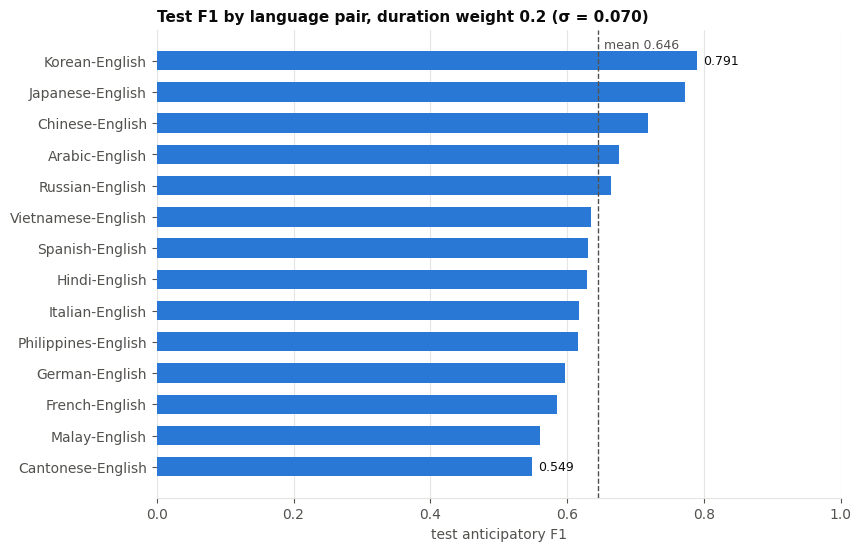

,language_pair,test_f1,precision,recall,duration_accuracy,switch_positions
0,Cantonese-English,0.5491,0.5348,0.5642,0.6078,436
1,Malay-English,0.5602,0.5595,0.5609,0.5457,788
2,French-English,0.5846,0.6280,0.5469,0.6102,821
3,German-English,0.5962,0.6235,0.5712,0.6365,751
4,Philippines-English,0.6166,0.5735,0.6667,0.5820,1299
5,Italian-English,0.6173,0.6675,0.5742,0.6435,937
6,Hindi-English,0.6290,0.5963,0.6655,0.6485,293
7,Spanish-English,0.6299,0.7015,0.5716,0.6149,740
8,Vietnamese-English,0.6348,0.6236,0.6465,0.5675,874
9,Russian-English,0.6639,0.6761,0.6521,0.6384,365


In [15]:
if test_path.exists():
    result = read_json(test_path)
    by_pair = pd.DataFrame([
        {"language_pair": pair, "test_f1": m["anticipatory_f1"], "precision": m["precision"], "recall": m["recall"],
         "duration_accuracy": m["duration_accuracy"], "switch_positions": m["positive_support"]}
        for pair, m in result["by_language_pair"].items()
    ]).sort_values("test_f1").reset_index(drop=True)
    by_pair.to_csv(OUT_DIR / "selected_test_by_pair.csv", index=False)

    macro = by_pair.test_f1.mean()
    fig, ax = plt.subplots(figsize=(8.5, 5.4), constrained_layout=True)
    ax.barh(by_pair.language_pair, by_pair.test_f1, height=0.62, color=SERIES[0], zorder=3)
    ax.axvline(macro, color=INK_MUTED, lw=1, ls="--", zorder=4)
    ax.annotate(f"mean {macro:.3f}", (macro, len(by_pair) - 0.5), textcoords="offset points", xytext=(4, 0),
                va="center", color=INK_MUTED, fontsize=9)
    for i in (0, len(by_pair) - 1):  # label the weakest and strongest pairs
        ax.annotate(f"{by_pair.test_f1[i]:.3f}", (by_pair.test_f1[i], i), textcoords="offset points", xytext=(4, 0),
                    va="center", color=INK, fontsize=9)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(1.0, by_pair.test_f1.max() * 1.1))
    ax.set_xlabel("test anticipatory F1")
    ax.set_title(f"Test F1 by language pair, duration weight {result['selected_candidate']['duration_weight']:g} "
                 f"(σ = {result['universality_std']:.3f})")
    fig.savefig(FIG_DIR / "selected_test_f1_by_pair.png", dpi=200)
    plt.show()
    display(by_pair.round(4))
else:
    print("No test result yet.")

## 11. Download the results

Zips `results/<RUN_NAME>/` (JSON, CSV, Markdown, figures; no checkpoints). Unzip it at the repository root.
The selected checkpoint stays in `MyDrive/SwitchLingua/checkpoints/<RUN_NAME>/`; do not commit it.

These runs use CUDA, batch 32 and max length 128, so report them separately from the Mac MPS sweep in
`results/loss_weight_ablation_full/` (batch 8 / max length 96).

In [16]:
archive = shutil.make_archive(f"/content/{RUN_NAME}", "zip", root_dir=STORE, base_dir=f"results/{RUN_NAME}")
print("Created", archive)
print("If the download does not start: Files panel (left sidebar) > right-click the zip > Download"
      + (f", or copy the folder from Google Drive: {OUT_DIR}" if USE_DRIVE else "."))
try:
    from google.colab import files
    files.download(archive)
except Exception as error:  # the browser download is flaky; the results are already saved
    print(f"Browser download failed ({type(error).__name__}); use one of the options above.")

Created /content/loss_weight_ablation_colab_fp32.zip
If the download does not start: Files panel (left sidebar) > right-click the zip > Download.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>